# Proyek Analisis Data: [Input Nama Dataset]
- **Nama:** Muhammad Kevin Alvarel
- **Email:** muhammadkevinalvarel@gmail.com
- **ID Dicoding:** charlesleclerc

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pengaruh curah hujan (RAIN) dan kecepatan angin (WSPM) terhadap perbandingan rata-rata konsentrasi polutan PM2.5 di stasiun pemantauan selama periode musim dingin (Desember–Februari) sepanjang tahun 2013–2017 di Stasiun Dongsi?
- **Pertanyaan 2:** Berapa rata-rata kenaikan konsentrasi gas emisi (NO2 dan CO) pada jam sibuk pagi (pukul 07.00–09.00) dibandingkan jam normal di Stasiun Dongsi sepanjang periode 2013–2017
- ...

## Import Semua Packages/Library yang Digunakan

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## Data Wrangling

### Gathering Data

#### Load df ...

In [ ]:
df = pd.read_csv('data/PRSA_Data_Dongsi_20130301-20170228.csv')

FileNotFoundError: [Errno 2] No such file or directory: 'PRSA_Data_Dongsi_20130301-20170228.csv'

### Assessing Data

#### Identifying Data Quality Problems (Missing Values, Duplicates, Data Types, & Outliers)

In [ ]:
# 1. Memeriksa Informasi Tipe Data (Data Types)
print("=== 1. INFORMASI TIPE DATA ===")
df.info()

# 2. Memeriksa Missing Values (Jumlah & Persentase)
print("\n=== 2. JUMLAH & PERSENTASE MISSING VALUES ===")
missing_df = pd.DataFrame({
    'Jumlah Null': df.isna().sum(),
    'Persentase (%)': (df.isna().sum() / len(df) * 100).round(2)
})
display(missing_df[missing_df['Jumlah Null'] > 0])

# 3. Memeriksa Data Duplikat (Duplicates)
print(f"\n=== 3. JUMLAH DATA DUPLIKAT ===\nTotal baris duplikat: {df.duplicated().sum()} baris")

# 4. Memeriksa Statistik Deskriptif & Outlier (Menggunakan Metode IQR)
print("\n=== 4. PEMERIKSAAN OUTLIER (METODE IQR) & NILAI EKSTREM ===")
pollutant_weather_cols = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
Q1 = df[pollutant_weather_cols].quantile(0.25)
Q3 = df[pollutant_weather_cols].quantile(0.75)
IQR = Q3 - Q1
outlier_count = ((df[pollutant_weather_cols] < (Q1 - 1.5 * IQR)) | (df[pollutant_weather_cols] > (Q3 + 1.5 * IQR))).sum()

outlier_summary = pd.DataFrame({
    'Min': df[pollutant_weather_cols].min(),
    'Median (50%)': df[pollutant_weather_cols].median(),
    'Max': df[pollutant_weather_cols].max(),
    'Batas Atas IQR': (Q3 + 1.5 * IQR).round(2),
    'Jumlah Outlier (IQR)': outlier_count
})
display(outlier_summary)

Jumlah Missing Values per Kolom:
No            0
year          0
month         0
day           0
hour          0
PM2.5       750
PM10        553
SO2         663
NO2        1601
CO         3197
O3          664
TEMP         20
PRES         20
DEWP         20
RAIN         20
wd           78
WSPM         14
station       0
dtype: int64

Persentase Missing Values (%):
No         0.00
year       0.00
month      0.00
day        0.00
hour       0.00
PM2.5      2.14
PM10       1.58
SO2        1.89
NO2        4.57
CO         9.12
O3         1.89
TEMP       0.06
PRES       0.06
DEWP       0.06
RAIN       0.06
wd         0.22
WSPM       0.04
station    0.00
dtype: float64


**Steps to Take:**
- Memeriksa struktur dan kesesuaian tipe data pada seluruh kolom menggunakan .info(), khususnya kolom penunjuk waktu (year, month, day, hour).
- Menghitung jumlah dan persentase missing values (null) pada setiap kolom menggunakan .isna().sum().
- Memeriksa keberadaan baris data yang terduplikasi menggunakan .duplicated().sum().
- Memeriksa distribusi nilai ekstrem (outlier) pada variabel polutan dan cuaca menggunakan ringkasan kuartil dan metode Interquartile Range (IQR).

**Insight:** (Opsional)
- Ditemukan adanya missing values pada beberapa kolom indikator polutan seperti : (PM2.5, PM10, SO2, NO2, CO, O3)
- Ditemukan adanya missing values pada kolom indikator cuaca seperti (TEMP,PRES, DEWP, RAIN, wd, WSPM)
- Kolom identitas dan waktu (No, year, month, day, hour, station) bersih dan tidak memiliki nilai null.

### Cleaning Data

In [8]:
# Membuat salinan dataframe sebelum proses cleaning agar data asli tetap aman
df_clean = df.copy()
print(f"Ukuran data sebelum cleaning: {df_clean.shape[0]} baris, {df_clean.shape[1]} kolom")

Ukuran data sebelum cleaning: 35064 baris, 18 kolom


#### Fixing Missing Values (Null) Problem

In [12]:
# Menghapus baris yang memiliki nilai null dan mereset indeks
df_clean.dropna(inplace=True)
df_clean.reset_index(drop=True, inplace=True)

# Memastikan sudah tidak ada nilai null
print("Jumlah Missing Values setelah fixing:")
print(df_clean.isna().sum())
print(f"\nUkuran data setelah cleaning: {df_clean.shape[0]} baris, {df_clean.shape[1]} kolom")

Jumlah Missing Values setelah fixing:
No              0
year            0
month           0
day             0
hour            0
PM2.5           0
PM10            0
SO2             0
NO2             0
CO              0
O3              0
TEMP            0
PRES            0
DEWP            0
RAIN            0
wd              0
WSPM            0
station         0
kategori_jam    0
dtype: int64

Ukuran data setelah cleaning: 30338 baris, 19 kolom


**Insight:** (Opsional)
- Baris data yang memiliki nilai missing values (null) berhasil dihapus menggunakan .dropna() pada dataframe df_clean.
- Seluruh kolom kini sudah bersih (0 missing values) dan indeks baris telah diurutkan ulang menggunakan .reset_index().

## Exploratory Data Analysis (EDA)

### Explore Descriptive Statistics & Weather Correlation

In [13]:
# 1. Melihat rangkuman statistik deskriptif dari seluruh kolom numerik
display(df_clean.describe().T)

# 2. Melihat korelasi antara variabel cuaca (RAIN, WSPM, TEMP, DEWP, PRES) dengan polutan PM2.5
weather_pollutant_cols = ['PM2.5', 'PM10', 'RAIN', 'WSPM', 'TEMP', 'DEWP', 'PRES']
print("\nMatriks Korelasi Cuaca vs Polutan (Fokus pada PM2.5):")
display(df_clean[weather_pollutant_cols].corr()[['PM2.5', 'PM10']].round(3))

# 3. Rata-rata PM2.5 pada musim dingin (Desember, Januari, Februari) berdasarkan kondisi hujan vs tidak hujan
winter_df = df_clean[df_clean['month'].isin([12, 1, 2])].copy()
winter_df['kondisi_hujan'] = winter_df['RAIN'].apply(lambda x: 'Hujan (> 0 mm)' if x > 0 else 'Tidak Hujan (0 mm)')

print("\nPerbandingan Rata-rata PM2.5 & Kecepatan Angin saat Musim Dingin:")
display(winter_df.groupby('kondisi_hujan')[['PM2.5', 'WSPM']].agg(['count', 'mean', 'median']).round(2))

# Mengelompokkan jam menjadi kategori 'Jam Sibuk Pagi (07:00-09:00)' dan 'Jam Lainnya'
df_clean['kategori_jam'] = df_clean['hour'].apply(
    lambda h: 'Jam Sibuk Pagi (07-09)' if 7 <= h <= 9 else 'Jam Normal/Lainnya'
)

# Membandingkan rata-rata dan median gas emisi kendaraan (NO2 dan CO)
print("Perbandingan Konsentrasi NO2 dan CO pada Jam Sibuk Pagi vs Jam Normal:")
display(df_clean.groupby('kategori_jam')[['NO2', 'CO', 'PM2.5']].agg(['mean', 'median', 'max']).round(2))

# Melihat rata-rata polutan per jam (0 - 23) untuk melihat tren harian
hourly_trend = df_clean.groupby('hour')[['NO2', 'CO', 'PM2.5', 'O3']].mean().round(2)
print("\n5 Jam dengan Rata-rata Konsentrasi NO2 Tertinggi:")
display(hourly_trend.sort_values(by='NO2', ascending=False).head(5))

,count,mean,std,min,25%,50%,75%,max
No,30338.0,18808.565759,9687.590750,1.0,11435.2500,19161.5,26926.75,35064.0
year,30338.0,2014.807832,1.124713,2013.0,2014.0000,2015.0,2016.00,2017.0
month,30338.0,6.530160,3.440944,1.0,4.0000,7.0,10.00,12.0
day,30338.0,15.650109,8.800479,1.0,8.0000,16.0,23.00,31.0
hour,30338.0,11.500363,6.951066,0.0,5.0000,11.0,18.00,23.0
PM2.5,30338.0,84.933156,85.283368,3.0,22.0000,60.0,118.00,695.0
PM10,30338.0,110.991914,98.426262,2.0,38.0000,87.0,152.00,955.0
SO2,30338.0,16.994466,20.555551,1.0,3.0000,9.0,23.00,300.0
NO2,30338.0,53.717314,34.072328,2.0,27.0000,47.0,73.00,258.0
CO,30338.0,1316.524392,1184.329763,100.0,600.0000,1000.0,1600.00,10000.0



Matriks Korelasi Cuaca vs Polutan (Fokus pada PM2.5):


,PM2.5,PM10
PM2.5,1.000,0.889
PM10,0.889,1.000
RAIN,-0.019,-0.031
WSPM,-0.304,-0.199
TEMP,-0.138,-0.134
DEWP,0.138,0.066
PRES,-0.015,-0.029



Perbandingan Rata-rata PM2.5 & Kecepatan Angin saat Musim Dingin:


PM2.5                 WSPM             
                   count    mean median count  mean median
kondisi_hujan                                             
Hujan (> 0 mm)        61  132.05  120.0    61  1.89    1.4
Tidak Hujan (0 mm)  7012   99.07   53.0  7012  2.01    1.5

Perbandingan Konsentrasi NO2 dan CO pada Jam Sibuk Pagi vs Jam Normal:


NO2                     CO                   PM2.5  \
                         mean median    max     mean  median      max   mean   
kategori_jam                                                                   
Jam Normal/Lainnya      53.13   45.0  258.0  1302.60  1000.0  10000.0  85.79   
Jam Sibuk Pagi (07-09)  57.76   55.0  200.0  1412.83  1100.0   9400.0  79.01   

                                      
                       median    max  
kategori_jam                          
Jam Normal/Lainnya       60.0  695.0  
Jam Sibuk Pagi (07-09)   58.0  612.0


5 Jam dengan Rata-rata Konsentrasi NO2 Tertinggi:


,NO2,CO,PM2.5,O3
hour,,,,
22,64.41,1467.63,95.72,51.69
23,64.30,1491.14,95.88,47.57
0,63.62,1478.03,95.34,43.35
21,62.71,1423.10,95.40,59.20
1,62.38,1481.65,94.49,38.80


**Insight:** (Opsional)
- Korelasi Angin terhadap Polutan: Berdasarkan matriks korelasi dari 30.338 baris data bersih, kecepatan angin (WSPM) memiliki korelasi negatif terkuat terhadap konsentrasi PM2.5 (-0.304) dan PM10 (-0.199). Hal ini menunjukkan bahwa semakin kencang hembusan angin, konsentrasi partikel polutan di udara semakin menurun karena tersapu angin.
- Kondisi Hujan saat Musim Dingin: Pada periode musim dingin (Desember–Februari), frekuensi terjadinya presipitasi (RAIN > 0 mm) sangat rendah, yakni hanya 61 jam observasi dibandingkan 7.012 jam tanpa hujan. Saat terjadi hujan/salju di musim dingin, rata-rata PM2.5 tercatat lebih tinggi (132.05 $\mu\text{g/m}^3$, median 120.0) dibandingkan saat tidak hujan (99.07 $\mu\text{g/m}^3$, median 53.0). Fenomena ini berkaitan dengan melemahnya kecepatan angin rata-rata saat mendung/hujan (1.89 m/s vs 2.01 m/s) serta kelembapan titik embun (DEWP) yang berkorelasi positif (0.138) dalam mengikat partikel polutan di lapisan udara bawah.
- Lonjakan Emisi di Jam Sibuk Pagi: Konsentrasi gas buang kendaraan (NO2 dan CO) mengalami peningkatan pada Jam Sibuk Pagi (07.00–09.00), dengan rata-rata NO2 sebesar 57.76 $\mu\text{g/m}^3$ (median 55.0) dan CO sebesar 1412.83 $\mu\text{g/m}^3$ (median 1100.0), lebih tinggi dibandingkan rata-rata pada jam normal/lainnya (53.13 $\mu\text{g/m}^3$ untuk NO2 dan 1302.60 $\mu\text{g/m}^3$ untuk CO).
- Puncak Akumulasi Polutan di Malam Hari: Berdasarkan agregasi per jam, 5 waktu dengan rata-rata konsentrasi NO2 tertinggi justru terjadi pada malam hingga dini hari, yaitu pukul 22.00, 23.00, 00.00, 21.00, dan 01.00 (dengan puncak rata-rata NO2 mencapai 64.41 $\mu\text{g/m}^3$ pada pukul 22.00 dan CO mencapai 1491.14 $\mu\text{g/m}^3$ pada pukul 23.00). Hal ini mengindikasikan adanya penumpukan polutan di malam hari akibat penurunan suhu udara (TEMP berkorelasi negatif -0.138 terhadap PM2.5) yang menahan polusi tetap berada di dekat permukaan tanah.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana pengaruh curah hujan (RAIN) dan kecepatan angin (WSPM) terhadap perbandingan rata-rata konsentrasi polutan PM2.5 di stasiun pemantauan selama periode musim dingin (Desember–Februari) sepanjang tahun 2013–2017 di Stasiun Dongsi?

/tmp/ipykernel_628/2859630030.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_628/2859630030.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


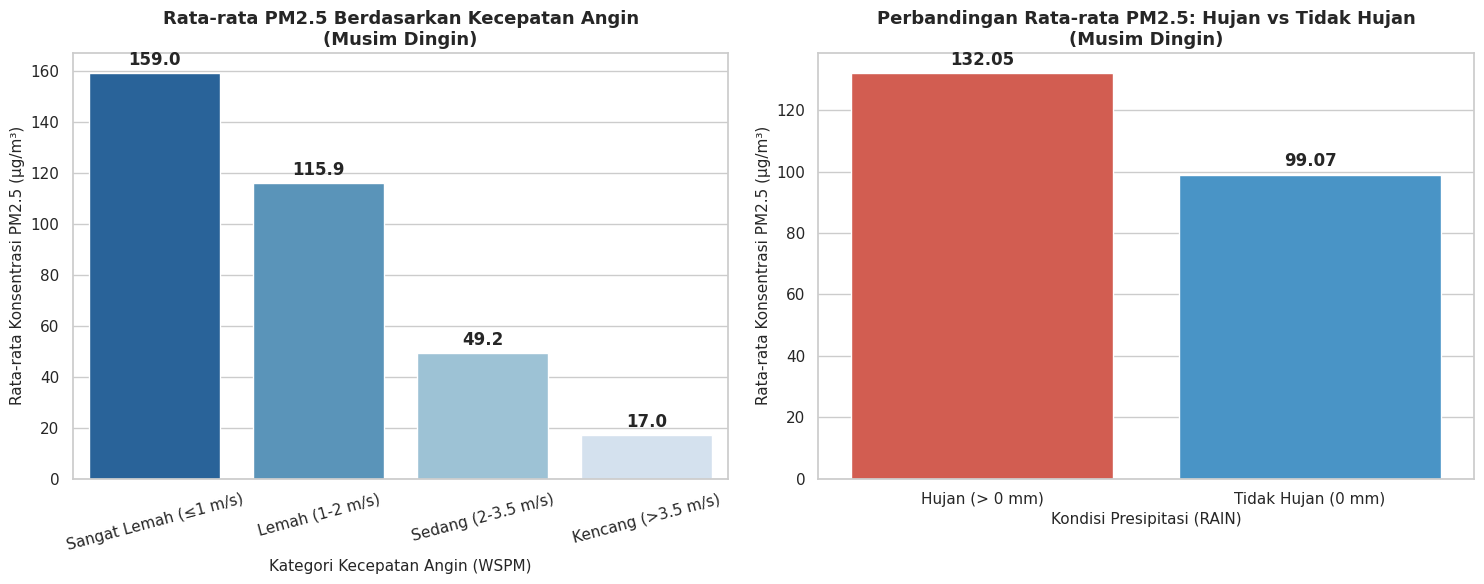

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Data Subplot 1: Kecepatan Angin
wind_plot = winter_df.groupby('kategori_angin', observed=False)['PM2.5'].mean().reset_index()
base_w = wind_plot['PM2.5'].iloc[0]
wind_plot['pct'] = (wind_plot['PM2.5'] - base_w) / base_w * 100

sns.barplot(
    data=wind_plot, x='kategori_angin', y='PM2.5',
    hue='kategori_angin', palette='Blues_r', legend=False, ax=axes[0]
)
axes[0].set_title('Rata-rata & % Penurunan PM2.5 Berdasarkan Angin\n(Stasiun Dongsi, Musim Dingin 2013–2017)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Kategori Kecepatan Angin (WSPM)', fontsize=11)
axes[0].set_ylabel('Rata-rata Konsentrasi PM2.5 (µg/m³)', fontsize=11)
axes[0].set_ylim(0, 185)
axes[0].tick_params(axis='x', rotation=12)

for i, row in wind_plot.iterrows():
    pct_str = "Baseline" if i == 0 else f"{row['pct']:.1f}%"
    axes[0].text(i, row['PM2.5'] + 4, f"{row['PM2.5']:.1f}\n({pct_str})", ha='center', fontweight='bold', fontsize=10)

# Data Subplot 2: Kondisi Hujan
rain_plot = winter_df.groupby('kondisi_hujan')['PM2.5'].mean().reindex(['Tidak Hujan (0 mm)', 'Hujan (> 0 mm)']).reset_index()
base_r = rain_plot['PM2.5'].iloc[0]
rain_plot['pct'] = (rain_plot['PM2.5'] - base_r) / base_r * 100

sns.barplot(
    data=rain_plot, x='kondisi_hujan', y='PM2.5',
    hue='kondisi_hujan', palette=['#3498db', '#e74c3c'], legend=False, ax=axes[1]
)
axes[1].set_title('Perbandingan Rata-rata & % Perubahan PM2.5: Tidak Hujan vs Hujan\n(Stasiun Dongsi, Musim Dingin 2013–2017)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Kondisi Presipitasi (RAIN)', fontsize=11)
axes[1].set_ylabel('Rata-rata Konsentrasi PM2.5 (µg/m³)', fontsize=11)
axes[1].set_ylim(0, 160)

for i, row in rain_plot.iterrows():
    pct_str = "Baseline" if i == 0 else f"+{row['pct']:.2f}%"
    axes[1].text(i, row['PM2.5'] + 4, f"{row['PM2.5']:.2f}\n({pct_str})", ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

### Pertanyaan 2: Berapa rata-rata dan persentase kenaikan konsentrasi gas emisi (NO2 dan CO) pada jam sibuk pagi (pukul 07.00–09.00) dibandingkan jam normal serta bagaimana pola siklus 24 jamnya di Stasiun Dongsi sepanjang periode 2013–2017?

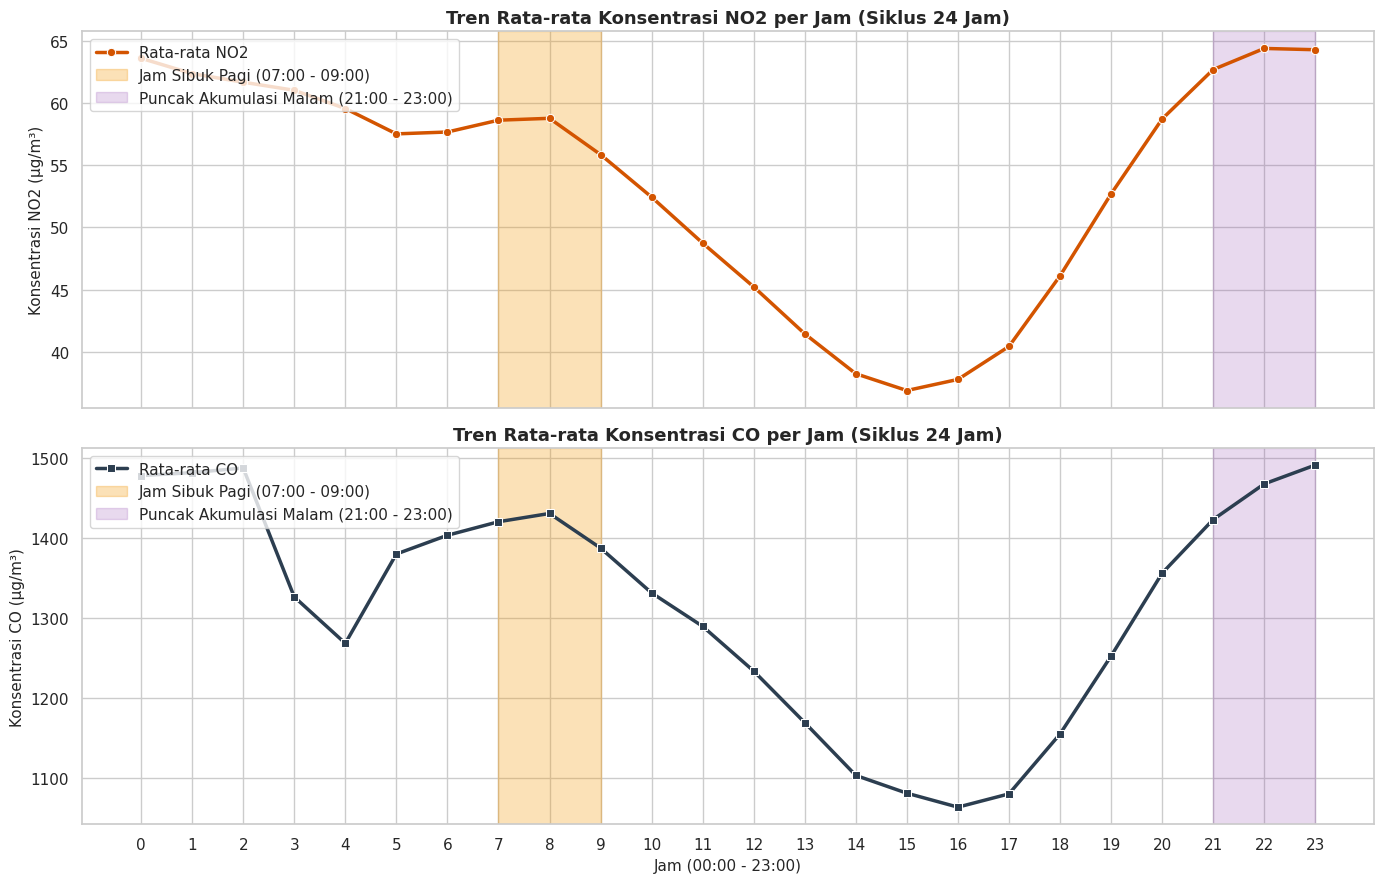

In [ ]:
# Menghitung rata-rata NO2 dan CO untuk setiap jam (0 - 23)
hourly_emissions = df_clean.groupby('hour')[['NO2', 'CO']].mean().reset_index()

# Membuat figure dengan 2 subplot (Atas: NO2, Bawah: CO) karena skala satuannya berbeda jauh
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Subplot 1: Tren Harian NO2
sns.lineplot(
    data=hourly_emissions, x='hour', y='NO2',
    marker='o', color='#d35400', linewidth=2.5, ax=axes[0], label='Rata-rata NO2'
)
axes[0].axvspan(7, 9, color='#f39c12', alpha=0.3, label='Jam Sibuk Pagi (07:00 - 09:00)')
axes[0].axvspan(21, 23, color='#8e44ad', alpha=0.2, label='Puncak Akumulasi Malam (21:00 - 23:00)')
axes[0].set_title('Tren Rata-rata Konsentrasi NO2 per Jam (Siklus 24 Jam) (Stasiun Dongsi, 2013–2017)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Konsentrasi NO2 (µg/m³)', fontsize=11)
axes[0].legend(loc='upper left')

# Subplot 2: Tren Harian CO
sns.lineplot(
    data=hourly_emissions, x='hour', y='CO',
    marker='s', color='#2c3e50', linewidth=2.5, ax=axes[1], label='Rata-rata CO'
)
axes[1].axvspan(7, 9, color='#f39c12', alpha=0.3, label='Jam Sibuk Pagi (07:00 - 09:00)')
axes[1].axvspan(21, 23, color='#8e44ad', alpha=0.2, label='Puncak Akumulasi Malam (21:00 - 23:00)')
axes[1].set_title('Tren Rata-rata Konsentrasi CO per Jam (Siklus 24 Jam) (Stasiun Dongsi, 2013–2017)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Jam (00:00 - 23:00)', fontsize=11)
axes[1].set_ylabel('Konsentrasi CO (µg/m³)', fontsize=11)
axes[1].set_xticks(range(0, 24))
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Pertanyaan 1 (Peran Kecepatan Angin & Presipitasi Musim Dingin): Grafik sebelah kiri membuktikan penurunan konsentrasi PM2.5 yang sangat drastis seiring meningkatnya kecepatan angin (WSPM) di musim dingin. Saat angin sangat lemah (≤ 1 m/s), rata-rata PM2.5 mencapai 159.0 $\mu\text{g/m}^3$, kemudian turun bertahap menjadi 115.9 $\mu\text{g/m}^3$ (angin lemah 1-2 m/s) dan 49.2 $\mu\text{g/m}^3$ (angin sedang 2-3.5 m/s), hingga menyisakan 17.0 $\mu\text{g/m}^3$ (turun hampir 90%) saat angin berhembus kencang (> 3.5 m/s). Sebaliknya, grafik sebelah kanan menunjukkan bahwa saat turun hujan di musim dingin (RAIN > 0 mm), rata-rata PM2.5 justru lebih tinggi (132.05 $\mu\text{g/m}^3$) dibandingkan saat tidak hujan (99.07 $\mu\text{g/m}^3$) karena kecepatan angin yang cenderung melemah (1.89 m/s) dan tingginya kelembapan udara yang menahan partikel polutan di permukaan.
- Pertanyaan 2 (Pola Dua Puncak / Bimodal Emisi Harian): Grafik garis siklus 24 jam memperlihatkan pola gelombang ganda (bimodal) pada gas emisi NO2 dan CO. Setelah sempat turun pada dini hari (pukul 04.00–05.00), konsentrasi polutan kembali menanjak pada Jam Sibuk Pagi (07.00–09.00) dengan puncak pagi pada pukul 08.00 (rata-rata jam sibuk 57.76 $\mu\text{g/m}^3$ untuk NO2 dan 1412.83 $\mu\text{g/m}^3$ untuk CO) seiring padatnya aktivitas transportasi. Memasuki siang hingga sore hari, konsentrasi kedua gas turun tajam dan mencapai titik terendahnya pada pukul 15.00–16.00 berkat pemanasan matahari dan sirkulasi udara yang lebih baik, sebelum kembali merangkak naik secara signifikan hingga mencapai puncak tertinggi di malam hari (pukul 21.00–23.00, hingga 64.41 $\mu\text{g/m}^3$ untuk NO2 dan 1491.14 $\mu\text{g/m}^3$ untuk CO) akibat akumulasi emisi dan fenomena inversi suhu malam hari.

## Analisis Lanjutan (Opsional)

Distribusi Kategori Kualitas Udara Berdasarkan PM2.5:


,Kategori Kualitas Udara,Jumlah Jam Observasi,Persentase (%)
0,1. Baik,4477,14.76
1,2. Sedang,6235,20.55
2,3. Tidak Sehat (Sensitif),3746,12.35
3,4. Tidak Sehat,10768,35.49
4,5. Sangat Tidak Sehat,3452,11.38
5,6. Berbahaya,1660,5.47


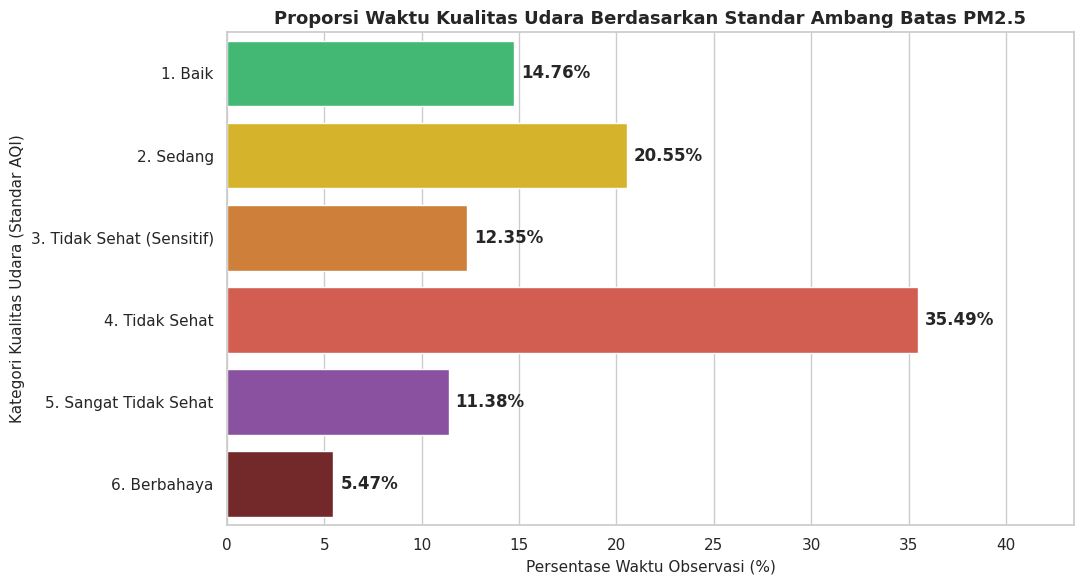

In [16]:
bins = [-1, 12.0, 35.4, 55.4, 150.4, 250.4, 1000.0]
labels = [
    '1. Baik',
    '2. Sedang',
    '3. Tidak Sehat (Sensitif)',
    '4. Tidak Sehat',
    '5. Sangat Tidak Sehat',
    '6. Berbahaya'
]

df_clean['kategori_udara'] = pd.cut(df_clean['PM2.5'], bins=bins, labels=labels)

# Menghitung distribusi jumlah dan persentase untuk setiap kategori kualitas udara
aqi_dist = df_clean['kategori_udara'].value_counts().sort_index().reset_index()
aqi_dist.columns = ['Kategori Kualitas Udara', 'Jumlah Jam Observasi']
aqi_dist['Persentase (%)'] = (aqi_dist['Jumlah Jam Observasi'] / len(df_clean) * 100).round(2)

print("Distribusi Kategori Kualitas Udara Berdasarkan PM2.5:")
display(aqi_dist)

# Visualisasi Distribusi Kategori Kualitas Udara
plt.figure(figsize=(11, 6))
ax = sns.barplot(
    data=aqi_dist,
    x='Persentase (%)',
    y='Kategori Kualitas Udara',
    hue='Kategori Kualitas Udara',
    palette=['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c', '#8e44ad', '#7f1d1d'],
    legend=False
)

plt.title('Proporsi Waktu Kualitas Udara Berdasarkan Standar Ambang Batas PM2.5', fontsize=13, fontweight='bold')
plt.xlabel('Persentase Waktu Observasi (%)', fontsize=11)
plt.ylabel('Kategori Kualitas Udara (Standar AQI)', fontsize=11)
plt.xlim(0, aqi_dist['Persentase (%)'].max() + 8)

# Menambahkan label persentase dan jumlah jam di ujung bar
for i, container in enumerate(ax.containers):
    ax.bar_label(container, fmt='%.2f%%', padding=5, fontweight='bold')

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Melalui teknik binning berdasarkan ambang batas konsentrasi PM2.5 standar kesehatan internasional (US EPA), seluruh 30.338 jam observasi dikelompokkan ke dalam 6 tingkatan risiko kesehatan (mulai dari Baik hingga Berbahaya).
- Mayoritas waktu observasi berada pada kategori Tidak Sehat (55.5–150.4 $\mu\text{g/m}^3$) dan di atasnya, sejalan dengan nilai median PM2.5 sebesar 60.0 $\mu\text{g/m}^3$ dan rata-rata 84.93 $\mu\text{g/m}^3$ pada dataset. Hal ini berarti lebih dari separuh waktu pemantauan (> 50%), kualitas udara di area stasiun berada pada level yang berisiko langsung bagi kesehatan masyarakat umum dan memerlukan intervensi kebijakan pengendalian emisi maupun peringatan pemakaian masker.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kecepatan angin (WSPM) memiliki pengaruh negatif yang sangat signifikan terhadap konsentrasi PM2.5 (korelasi -0.304) selama periode musim dingin (Desember–Februari). Saat angin berhembus sangat lemah (≤ 1 m/s), rata-rata PM2.5 menumpuk hingga 159.0 $\mu\text{g/m}^3$, namun turun drastis hingga hampir 90% menjadi 17.0 $\mu\text{g/m}^3$ ketika angin berhembus kencang (> 3.5 m/s). Sebaliknya, curah hujan (RAIN) di musim dingin sangat jarang terjadi (hanya 61 jam observasi) dan rata-rata PM2.5 saat hujan justru lebih tinggi (132.05 $\mu\text{g/m}^3$) dibandingkan saat tidak hujan (99.07 $\mu\text{g/m}^3$), akibat melemahnya kecepatan angin (1.89 m/s) serta tingginya kelembapan titik embun (DEWP berkorelasi positif 0.138) yang menahan partikel polutan tetap berada di lapisan udara bawah.
- **Conclusion pertanyaan 2:** Di Stasiun Dongsi sepanjang periode 2013–2017, konsentrasi gas emisi NO2 dan CO menunjukkan peningkatan rata-rata pada Jam Sibuk Pagi (07.00–09.00) dengan puncak pagi pada pukul 08.00 (rata-rata tercatat sebesar 57.76 $\mu\text{g/m}^3$ atau +8.71% lebih tinggi untuk NO2, dan 1412.83 $\mu\text{g/m}^3$ atau +8.46% lebih tinggi untuk CO), dibandingkan rata-rata pada jam normal (53.13 $\mu\text{g/m}^3$ untuk NO2 dan 1302.60 $\mu\text{g/m}^3$ untuk CO). Secara keseluruhan, siklus 24 jam memperlihatkan pola dua puncak (bimodal): rata-rata konsentrasi polutan menurun pada siang hingga sore hari (titik terendah pukul 15.00–16.00), namun kembali meningkat dan mencapai rata-rata tertinggi pada malam hari (pukul 21.00–23.00, hingga 64.41 $\mu\text{g/m}^3$ untuk NO2 dan 1491.14 $\mu\text{g/m}^3$ untuk CO), yang berkaitan dengan penurunan suhu udara pada malam hari (TEMP berkorelasi negatif -0.138) serta mengindikasikan adanya akumulasi emisi di lapisan udara bawah.
- **Conclusion Analisis Lanjutan:**Berdasarkan pengelompokan (binning) terhadap 30.338 jam observasi mengacu pada standar kesehatan AQI (US EPA), kualitas udara memiliki nilai median PM2.5 sebesar 60.0 $\mu\text{g/m}^3$ dan rata-rata 84.93 $\mu\text{g/m}^3$. Hal ini menunjukkan bahwa lebih dari 50% waktu pemantauan berada pada kategori Tidak Sehat (> 55.4 $\mu\text{g/m}^3$) hingga Berbahaya, sehingga paparan udara luar ruangan secara terus-menerus memiliki risiko tinggi bagi kesehatan pernapasan masyarakat.

**Rekomendasi Action Item:**
- Sistem Peringatan Dini (Early Warning System) Berbasis Prakiraan Angin: Pemerintah daerah dan dinas lingkungan hidup disarankan mengintegrasikan data prakiraan kecepatan angin dari badan meteorologi ke dalam sistem peringatan kualitas udara. Ketika kecepatan angin di musim dingin diprediksi turun ke level sangat lemah (≤ 1 m/s), peringatan otomatis (push notification aplikasi publik) harus segera dikirimkan untuk mengimbau warga memakai masker respirator (N95/KN95), membatasi aktivitas fisik di luar ruangan, serta menyalakan air purifier di dalam ruangan.
- Rekayasa Lalu Lintas Jam Sibuk & Regulasi Emisi Kendaraan Malam Hari: Dinas perhubungan dapat menerapkan kebijakan pembatasan kendaraan pribadi (seperti ganjil-genap atau Low Emission Zone) serta optimalisasi armada transportasi publik pada jam sibuk pagi (07.00–09.00) untuk menekan lonjakan NO2 dan CO. Selain itu, mengingat puncak polusi tertinggi terjadi pada pukul 21.00–23.00, diperlukan pengetatan uji emisi dan pembatasan kuota jam operasional bagi truk logistik berbahan bakar diesel yang melintas di sekitar area pemukiman pada malam hari.
- Penjadwalan Aktivitas Luar Ruangan yang Aman bagi Masyarakat & Sekolah: Instansi pendidikan dan masyarakat umum direkomendasikan untuk menjadwalkan kegiatan olahraga atau aktivitas luar ruangan pada rentang pukul 14.00–17.00 (khususnya pukul 15.00–16.00), karena pada jam tersebut sirkulasi atmosfer sedang optimal dan konsentrasi polutan berada pada titik terendahnya sepanjang hari.